# One Shot Vitis with Cheaper Models

In [58]:
# Imports
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
from scipy import stats

In [59]:
# Load data
df_oneshot_vitis_cheap = pd.read_csv('vitis_oneshot_cheap_models.csv')
df_oneshot_vitis_expensive = pd.read_csv('vitis_oneshot_expensive_models.csv')
# Calculate and add a column saying success for synthesis
df_oneshot_vitis_comb = pd.concat([df_oneshot_vitis_cheap, df_oneshot_vitis_expensive], ignore_index=True)
df_oneshot_vitis_comb['latency'] = pd.to_numeric(df_oneshot_vitis_comb['latency'], errors='coerce')
df_oneshot_vitis_comb['Success'] = ((df_oneshot_vitis_comb['latency'].notna()) & (df_oneshot_vitis_comb['latency'] > 5)).astype(int)

# Calculate the Successes and Group by model
success_counts_unsorted = df_oneshot_vitis_comb.groupby('model')['Success'].sum()
success_counts = df_oneshot_vitis_comb.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rates = (success_counts / total_tests) * 100
success_rates_unsorted = (success_counts_unsorted / total_tests) * 100

print(success_rates)

model
anthropic/claude-sonnet-4.5       90.099010
openai/gpt-5                      86.138614
google/gemini-2.5-flash           69.306931
deepseek/deepseek-chat-v3-0324    66.336634
x-ai/grok-4                       65.346535
deepseek/deepseek-r1-0528         47.524752
google/gemini-2.5-pro             45.544554
openai/gpt-4.1-mini               43.564356
x-ai/grok-code-fast-1             31.683168
qwen/qwen3-coder                  27.722772
Name: Success, dtype: float64


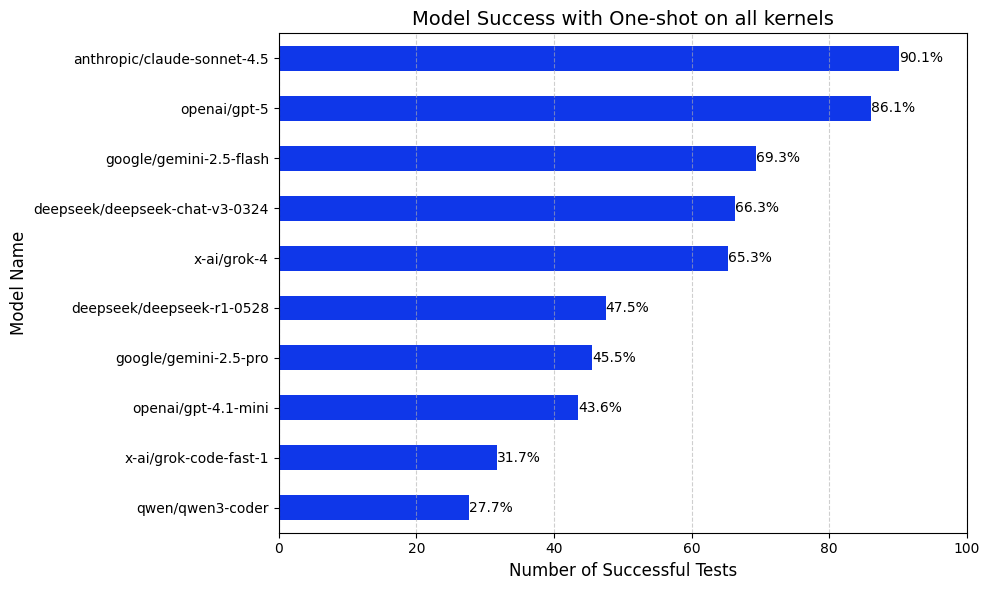

In [60]:
# Generate the Bar chart
plt.figure(figsize=(10,6))

success_rates.plot(kind='barh', color="#0f37e9" )
for index, value in enumerate(success_rates):
    label = f"{value:.1f}%"
    plt.text(value, index, label, va='center') # f' {value}' adds space after the bar
# Formatting and labels
plt.title(f'Model Success with One-shot on all kernels', fontsize=14)
plt.xlabel('Number of Successful Tests', fontsize=12)
plt.xlim(0,100)
plt.ylabel('Model Name', fontsize=12)
# Invert y-axis to put the highest performing model at the top
plt.gca().invert_yaxis() 
plt.grid(axis='x', linestyle='--', alpha=0.6) # Add light grid lines for readability
plt.tight_layout()

# Save and show the plot 
# plt.savefig('HLS_Model_Success_Bar_Chart.png')
plt.show()

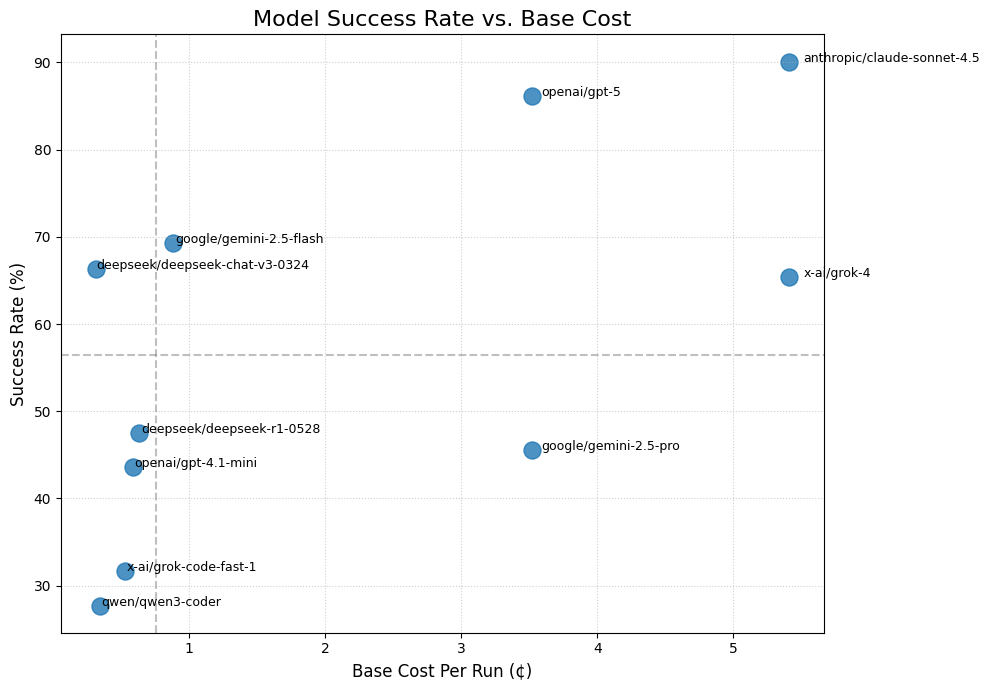

In [63]:
model_costs_data = {
    'Model': ['google/gemini-2.5-flash', 'deepseek/deepseek-chat-v3-0324', 'deepseek/deepseek-r1-0528', 'openai/gpt-4.1-mini', 'x-ai/grok-code-fast-1',  
              'qwen/qwen3-coder', 'openai/gpt-5', 'x-ai/grok-4', 'google/gemini-2.5-pro', 'anthropic/claude-sonnet-4.5'],
    'Base_Cost_Per_Run': [0.878, 0.311, 0.633, 0.586, 0.529, 0.346, 3.519, 5.408, 3.519, 5.408]
}
costs_df = pd.DataFrame(model_costs_data).set_index('Model')

combined_df = pd.DataFrame({
    'Success_Rate': success_rates,
    'Cost': costs_df['Base_Cost_Per_Run'] # Assuming this column name in your data
}).dropna() # Drop any model that might be missing one of the values

# --- 2. Generate the Scatter Plot ---

plt.figure(figsize=(10, 7))

# Create the scatter plot
plt.scatter(
    combined_df['Cost'], 
    combined_df['Success_Rate'], 
    s=150,  # Size of the points
    alpha=0.8,
    color='#1f77b4'
)

# --- 3. Labeling and Formatting for Cost-Effectiveness ---

# Add model labels to the points
for model, row in combined_df.iterrows():
    # Use model name as the label
    plt.annotate(
        model,
        (row['Cost'] * 1.02, row['Success_Rate']), # Offset label slightly to the right
        fontsize=9
    )


median_cost = combined_df['Cost'].median()
median_success = combined_df['Success_Rate'].median()
# Horizontal Line (Median Success)
plt.axhline(median_success, color='gray', linestyle='--', alpha=0.5)
# Vertical Line (Median Cost)
plt.axvline(median_cost, color='gray', linestyle='--', alpha=0.5)

# Final Plot Aesthetics
plt.title('Model Success Rate vs. Base Cost', fontsize=16)
plt.xlabel('Base Cost Per Run (¢)', fontsize=12)
plt.ylabel('Success Rate (%)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Save the plot
# plt.savefig('Model_Cost_Effectiveness_Scatter_Plot.png')
plt.show()

In [62]:
# Slope chart to show effect of RAG on Success
success_rates_RAG = {
    'Model': ['google/gemini-2.5-flash', 'deepseek/deepseek-chat-v3-0324', 'deepseek/deepseek-r1-0528', 'openai/gpt-4.1-mini', 'x-ai/grok-code-fast-1',  
              'qwen/qwen3-coder', 'openai/gpt-5', 'x-ai/grok-4', 'google/gemini-2.5-pro'],
    'rag_success': [79.3, 77.9, 57.5, 89, 52.34, 37.7, 90, 75.3, 50],
}
rag_success_df = pd.DataFrame(success_rates_RAG)
no_rag_success_df = 

rag_df = rag_success_df.sort_values(by='no_rag_success', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 10))

# Define the two points on the X-axis and their labels
x_positions = [0, 1]
x_labels = ['No RAG', 'RAG']


for index, row in rag_df.iterrows():
    
    # Get the two success rates for the current model
    no_rag = row['no_rag_success']
    rag = row['rag_success']
    model_name = row['Model']
    
    # Define color: Green for improvement, Red for decrease, Gray for no change
    color = 'green' if rag > no_rag else 'red' if rag < no_rag else 'gray'
    
    # a. Plot the connecting line and points
    plt.plot(x_positions, [no_rag, rag], 
             marker='o', # Use a circular marker for the endpoints
             color=color, 
             linewidth=1.5, 
             alpha=0.7)
    
    # b. Annotate the left side (No RAG rate and model name)
    plt.text(x_positions[0], no_rag, 
             f'{model_name} ({no_rag:.1f}%)', 
             ha='right', # Horizontal alignment: right of the point
             fontsize=10, 
             color=color, 
             fontweight='bold')
    
    # c. Annotate the right side (RAG rate and model name)
    plt.text(x_positions[1], rag, 
             f'({rag:.1f}%) {model_name}', 
             ha='left', # Horizontal alignment: left of the point
             fontsize=10, 
             color=color, 
             fontweight='bold')
    
    # Set X-axis ticks to only show the two defined points
plt.xticks(x_positions, x_labels, fontsize=14, fontweight='bold')

# Set Y-axis label and limits for good padding
plt.ylabel('Success Rate (%)', fontsize=12)
min_y = rag_df[['no_rag_success', 'rag_success']].min().min()
max_y = rag_df[['no_rag_success', 'rag_success']].max().max()
plt.ylim(min_y - 5, max_y + 5) 

# Remove chart borders (spines) for a cleaner academic look
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)

plt.title('Impact of RAG on Model Success Rate', fontsize=16)
plt.tight_layout()

plt.show() # Use this if you are running outside a script environment


SyntaxError: invalid syntax (2924689475.py, line 8)